# лабораторная работа 03: выравнивание Витерби и биграммная ЯМ

что делает блокнот:
- запускает `run_lab` на данных из `data/`.
- проверяет дописанные функции.
- сверяет файлы из `outputs/` с `outputs_reference/`.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import SVG, display

root = Path.cwd()
if not (root / "scripts").exists():
    root = root.parent
sys.path.insert(0, str(root))

from scripts.bigram_lm import BigramLM
from scripts.combine_candidate_scores import rank_candidates
from scripts.run_lab_03 import run_lab
from scripts.viterbi_alignment import viterbi_align

data_dir = root / "data"
out_dir = root / "outputs"
ref_dir = root / "outputs_reference"
print(root)

d:\documents\asr_labs_itmo\lab_03_ru


## запуск

что происходит в ячейке ниже:
- `run_lab` читает данные, считает выравнивание, обучает ЯМ и ранжирует кандидатов.
- результаты записываются в `outputs/`, сводка печатается целиком.

In [2]:
summary = run_lab(data_dir, out_dir)
print(json.dumps(summary, indent=2, ensure_ascii=False))

{
  "alignment_path": [
    0,
    1,
    1,
    2,
    3,
    4
  ],
  "alignment_total_cost": 3.0,
  "alternative_path_cost": 3.7,
  "candidate_rankings": {
    "0.0": [
      "acoustic_favorite",
      "language_favorite"
    ],
    "0.5": [
      "language_favorite",
      "acoustic_favorite"
    ],
    "1.0": [
      "language_favorite",
      "acoustic_favorite"
    ]
  },
  "note": "Стоимость и акустические баллы синтетические: это учебный пример, а не вывод модели."
}


## часть A: выравнивание Витерби

что показано ниже:
- входная матрица стоимостей эмиссии, строки это кадры, столбцы это состояния.
- тепловая карта с лучшим путём.
- таблица пути с накопленной стоимостью.

In [3]:
alignment = json.loads((data_dir / "toy_alignment_costs.json").read_text(encoding="utf-8"))
df = pd.DataFrame(alignment["costs"], index=alignment["frame_labels"], columns=alignment["state_labels"])
print(df.shape)
display(df)

(6, 5)


,sil_start,/y/,/e/,/s/,sil_end
f1,0.4,9.0,9.0,9.0,9.0
f2,9.0,0.7,9.0,9.0,9.0
f3,9.0,0.5,1.2,9.0,9.0
f4,9.0,9.0,0.6,9.0,9.0
f5,9.0,9.0,9.0,0.5,9.0
f6,9.0,9.0,9.0,9.0,0.3


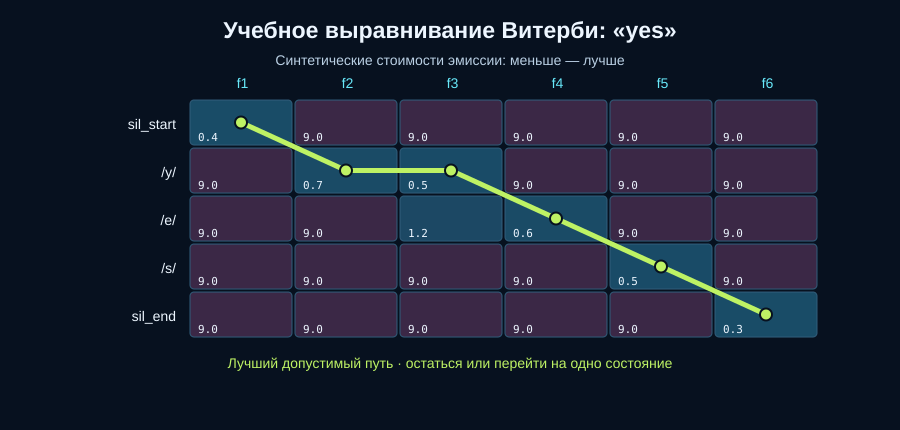

In [4]:
display(SVG(filename=str(out_dir / "viterbi_trellis.svg")))

In [5]:
df_path = pd.read_csv(out_dir / "alignment_path.csv")
display(df_path)
print("path:", [alignment["state_labels"][s] for s in summary["alignment_path"]])
print("best cost:", summary["alignment_total_cost"])
print("alternative cost:", summary["alternative_path_cost"])

,frame,state_index,state_label,emission_cost,path_cost_so_far
0,f1,0,sil_start,0.4,0.4
1,f2,1,/y/,0.7,1.1
2,f3,1,/y/,0.5,1.6
3,f4,2,/e/,0.6,2.2
4,f5,3,/s/,0.5,2.7
5,f6,4,sil_end,0.3,3.0


path: ['sil_start', '/y/', '/y/', '/e/', '/s/', 'sil_end']
best cost: 3.0
alternative cost: 3.7


### проверки

что проверяется:
- ожидаемый путь и стоимость из описания задания.
- при равных стоимостях выбирается «остаться», на искусственной матрице из нулей.

In [6]:
expected = ["sil_start", "/y/", "/y/", "/e/", "/s/", "sil_end"]
labels = [alignment["state_labels"][s] for s in summary["alignment_path"]]
assert labels == expected, labels
assert abs(summary["alignment_total_cost"] - 3.0) < 1e-9, summary["alignment_total_cost"]
assert summary["alignment_total_cost"] < summary["alternative_path_cost"]

path, cost = viterbi_align([[0, 0, 0]] * 4)
print(path, cost)
assert path == [0, 1, 2, 2]
print("viterbi checks passed")

[0, 1, 2, 2] 0.0
viterbi checks passed


## часть B: биграммная ЯМ

что показано ниже:
- размер словаря и число слов корпуса.
- распределение для одного контекста, сумма вероятностей по словарю.
- ручной расчёт одной вероятности по формуле add-k.
- отображение неизвестного слова в `<unk>` и вклад `</s>`.

In [7]:
corpus = (data_dir / "toy_lm_corpus.txt").read_text(encoding="utf-8").splitlines()
lm = BigramLM.train(corpus, k=0.5)
print("sentences:", len(corpus))
print("vocab size with <unk> and </s>:", len(lm.vocabulary))
print("has <s> in vocab:", "<s>" in lm.vocabulary)

sentences: 7
vocab size with <unk> and </s>: 10
has <s> in vocab: False


In [8]:
h = lm.context_counts.most_common(1)[0][0]
rows = []
for w in sorted(lm.vocabulary):
    rows.append({"w": w, "count": lm.bigram_counts[(h, w)], "p": lm.bigram_probability(h, w)})
df_h = pd.DataFrame(rows).sort_values("p", ascending=False)
print("context:", h, "| C(h):", lm.context_counts[h])
display(df_h.head(10))
print("sum of p over vocab:", df_h["p"].sum())
assert abs(df_h["p"].sum() - 1.0) < 1e-9

context: <s> | C(h): 7


,w,count,p
9,we,4,0.375000
8,they,3,0.291667
1,<unk>,0,0.041667
0,</s>,0,0.041667
2,coffee,0,0.041667
3,drink,0,0.041667
5,like,0,0.041667
4,green,0,0.041667
7,tea,0,0.041667
6,strong,0,0.041667


sum of p over vocab: 1.0


In [9]:
w = df_h.iloc[0]["w"]
by_hand = (lm.bigram_counts[(h, w)] + 0.5) / (lm.context_counts[h] + 0.5 * len(lm.vocabulary))
print(h, w, by_hand, lm.bigram_probability(h, w))
assert abs(by_hand - lm.bigram_probability(h, w)) < 1e-12

<s> we 0.375 0.375


In [10]:
s = corpus[0]
s_unk = s + " zzzqq"
print(s, "->", lm.sentence_logprob(s))
print(s_unk, "->", lm.sentence_logprob(s_unk))
print("target of unseen word:", lm._target("zzzqq"))
print("p(</s> | last word):", lm.bigram_probability(s.lower().split()[-1], "</s>"))

we drink green tea -> -1.91172031914013
we drink green tea zzzqq -> -3.953113004298355
target of unseen word: <unk>
p(</s> | last word): 0.55


In [11]:
cands = json.loads((data_dir / "toy_candidate_scores.json").read_text(encoding="utf-8"))
for c in cands:
    c["lm_log_score"] = lm.sentence_logprob(c["transcript"])
display(pd.DataFrame(cands))

,candidate_id,transcript,acoustic_log_score,lm_log_score
0,acoustic_favorite,we drink strong coffee,-1.0,-2.654739
1,language_favorite,we drink green tea,-1.2,-1.911720


## часть C: комбинирование оценок

что показано ниже:
- ранжирование кандидатов при весах ЯМ 0, 0.5 и 1.0.
- кандидат на первом месте для каждого веса.
- как меняются объединённые оценки при весе от 0 до 2.

In [12]:
df_c = pd.read_csv(out_dir / "candidate_scores.csv")
display(df_c)
display(df_c[df_c["rank"] == 1])

,lm_weight,rank,candidate_id,transcript,acoustic_log_score,lm_log_score,combined_log_score
0,0.0,1,acoustic_favorite,we drink strong coffee,-1.0,-2.654739,-1.000000
1,0.0,2,language_favorite,we drink green tea,-1.2,-1.911720,-1.200000
2,0.5,1,language_favorite,we drink green tea,-1.2,-1.911720,-2.155860
3,0.5,2,acoustic_favorite,we drink strong coffee,-1.0,-2.654739,-2.327369
4,1.0,1,language_favorite,we drink green tea,-1.2,-1.911720,-3.111720
5,1.0,2,acoustic_favorite,we drink strong coffee,-1.0,-2.654739,-3.654739


,lm_weight,rank,candidate_id,transcript,acoustic_log_score,lm_log_score,combined_log_score
0,0.0,1,acoustic_favorite,we drink strong coffee,-1.0,-2.654739,-1.00000
2,0.5,1,language_favorite,we drink green tea,-1.2,-1.911720,-2.15586
4,1.0,1,language_favorite,we drink green tea,-1.2,-1.911720,-3.11172


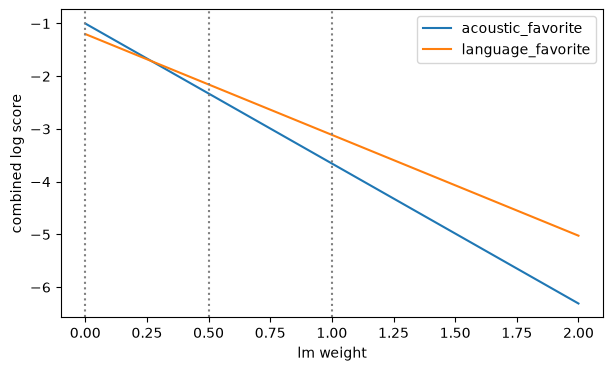

In [13]:
ws = [i / 20 for i in range(41)]
fig, ax = plt.subplots(figsize=(7, 4))
for c in cands:
    ax.plot(ws, [c["acoustic_log_score"] + w * c["lm_log_score"] for w in ws], label=c["candidate_id"])
for w in (0.0, 0.5, 1.0):
    ax.axvline(w, color="gray", ls=":")
ax.set_xlabel("lm weight")
ax.set_ylabel("combined log score")
ax.legend()
plt.show()

## сверка с outputs_reference

что сравнивается:
- текст четырёх файлов после приведения переводов строк.
- `summary.json` сравнивается как разобранный JSON.

In [14]:
for name in ["viterbi_trellis.svg", "alignment_path.csv", "candidate_scores.csv", "summary.json"]:
    if not (ref_dir / name).exists():
        print(name, "no reference")
        continue
    a = (out_dir / name).read_text(encoding="utf-8").replace("\r\n", "\n")
    b = (ref_dir / name).read_text(encoding="utf-8").replace("\r\n", "\n")
    if name.endswith(".json"):
        same = json.loads(a) == json.loads(b)
    else:
        same = a == b
    print(name, "match" if same else "DIFFERENT")

viterbi_trellis.svg match
alignment_path.csv match
candidate_scores.csv match
summary.json match


In [15]:
alt = [0, 1, 2, 2, 3, 4]
best = summary["alignment_path"]
alt_cost = sum(alignment["costs"][t][s] for t, s in enumerate(alt))
print("alternative by hand:", round(alt_cost, 3), "| from json:", summary["alternative_path_cost"])
print("frames where paths differ:", [alignment["frame_labels"][t] for t in range(len(best)) if best[t] != alt[t]])
print("cost difference:", round(summary["alternative_path_cost"] - summary["alignment_total_cost"], 3))

alternative by hand: 3.7 | from json: 3.7
frames where paths differ: ['f3']
cost difference: 0.7


In [16]:
rank0 = summary["candidate_rankings"]["0.0"]
by_id = {c["candidate_id"]: c for c in cands}
top, other = by_id[rank0[0]], by_id[rank0[1]]
w_cross = (top["acoustic_log_score"] - other["acoustic_log_score"]) / (other["lm_log_score"] - top["lm_log_score"])
print(top["candidate_id"], "loses first place to", other["candidate_id"], "at lm weight above", round(w_cross, 4))

acoustic_favorite loses first place to language_favorite at lm weight above 0.2692


## ответы на вопросы

что кодирует тепловая карта (вопрос 1):
- каждая клетка это стоимость эмиссии для пары кадр и состояние. чем темнее клетка, тем меньше стоимость и лучше соответствие.
- низкая стоимость: клетки f1 / sil_start и f6 / sil_end. обе тёмные, лучший путь проходит через них.
- высокая стоимость: клетка f1 / /y/, как и все клетки вне пути. они светлее остальных.

переходы на лучшем пути (вопрос 2):
- остаться: с f2 на f3 путь остаётся в `/y/`. на f3 добавляется только эмиссия `/y/`, это видно в таблице пути.
- перейти: с f1 на f2 путь идёт из `sil_start` в `/y/`. так же устроены переходы с f3 на f4, с f4 на f5 и с f5 на f6.
- кадров на один больше, чем состояний, поэтому остаться нужно ровно один раз.

лучший путь и альтернатива (вопрос 3):
- лучший путь держит `/y/` на двух кадрах подряд и уходит в `/e/` на f4.
- альтернатива уходит в `/e/` уже на f3. остальные кадры у путей совпадают.
- на f3 эмиссия `/e/` заметно дороже эмиссии `/y/`, поэтому альтернатива проигрывает. вся разница стоимостей набирается на этом кадре, числа в выводе ячейки выше.

лидеры при разных весах ЯМ (вопрос 4):
- при нулевом весе первым идёт `acoustic_favorite`. решает одна акустика.
- при среднем весе первым идёт `language_favorite`. акустическая, языковая и объединённая оценки обоих кандидатов в таблице части C.

причина смены лидера (вопрос 5):
- `acoustic_favorite` лучше по акустике, `language_favorite` лучше по ЯМ.
- при нулевом весе ЯМ не участвует, поэтому побеждает акустика.
- с ростом веса штраф ЯМ перевешивает акустическое преимущество. порядок меняется при весе выше порога из ячейки выше.
- объединённая оценка линейна по весу, поэтому две линии на графике пересекаются не более одного раза.
- данные синтетические: опыт показывает механику комбинирования оценок, но не качество распознавания.